# Parkinson's Disease Severity Prediction from Voice Recordings using SVR Optimised with Cuckoo Search

**Bio-Inspired Algorithms AAT (23DS7BSBIO)**, Group 15, Department of CSE (Data Science), B.M.S. College of Engineering

**Goal:** predict a patient's clinician-rated **motor UPDRS** score (Parkinson's symptom severity) from biomedical
voice measurements, so symptom progression can be monitored remotely from a phone recording.

**Method:** a Support Vector Regressor (RBF kernel) whose hyperparameters **and** input-feature subset are chosen jointly by
**Cuckoo Search**, implemented from scratch.

This notebook is the complete, executed record of the experiment:
1. Dataset, cleaning and preprocessing
2. Baselines without optimisation: mean predictor, linear regression, default SVR
3. Cuckoo Search (joint hyperparameter tuning + feature selection)
4. Random Search with the same budget (non-bio-inspired reference)
5. Baseline vs optimised comparison on the untouched test set
6. Learning curves of the default and optimised SVR
7. Robustness: 10 independent runs of both optimisers, with statistical tests

Before the SVR experiment, the Cuckoo Search operators are checked on four standard optimisation test functions.

All figures and numbers are also saved to `outputs/`.

## 0. Run information

In [1]:
import datetime, platform, subprocess, sys
import numpy as np, pandas as pd, scipy, sklearn
print("Run started :", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Machine     :", platform.platform())
print("CPU         :", subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip() or platform.processor())
print("Python      :", sys.version.split()[0])
print("Libraries   : NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| SciPy", scipy.__version__)

Run started : 2026-11-06 03:15:58
Machine     : macOS-27.0.1-arm64-arm-64bit-Mach-O
CPU         : Apple M4
Python      : 3.13.5
Libraries   : NumPy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | SciPy 1.18.1


## 1. Configuration

**Search budget.** Each optimiser run gets about 820 fitness evaluations (20 nests x 20 generations; Random Search
gets exactly the same number). An earlier run with only 170 evaluations (10 nests x 8 generations) left Cuckoo
Search and Random Search tied: 8 generations are too few for a guided search to pay off in a 21-dimensional space.
A budget study on three seeds showed Cuckoo Search pulling clearly ahead after about 500 evaluations, so the
budget was raised for **both** methods. The earlier runs are kept in `archive/`.

In [2]:
import json, time, inspect, warnings
from pathlib import Path
import joblib
from IPython.display import Image, Markdown, display
from scipy.stats import wilcoxon

from src import plots
from src.cuckoo import CuckooSearch
from src.data import TARGET, prepare_data
from src.metrics import compare, regression_metrics
from src.model import DEFAULT_PARAMS, baselines, build_svr
from src.random_search import random_search
from src.search_space import HYPERPARAMS, Objective, decode, default_position, dim

warnings.filterwarnings("ignore")
CONFIG = {
    "data": "data/parkinsons_updrs.data",
    "split_seed": 42,          # train/test split and CV folds
    "main_seed": 42,           # seed of the detailed run (sections 5-8)
    "nests": 20,               # Cuckoo Search population size
    "generations": 20,         # about 820 fitness evaluations per run (Random Search gets the same number)
    "pa": 0.25,                # probability a nest is discovered and abandoned
    "alpha": 1.0,              # Levy step-size scale
    "beta": 1.5,               # Levy exponent
    "cv_folds": 3,             # fitness = 3-fold CV RMSE on the training set
    "robustness_seeds": list(range(1, 11)),
}
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
timings, T0 = {}, time.time()
print(json.dumps(CONFIG, indent=2))

{
  "data": "data/parkinsons_updrs.data",
  "split_seed": 42,
  "main_seed": 42,
  "nests": 20,
  "generations": 20,
  "pa": 0.25,
  "alpha": 1.0,
  "beta": 1.5,
  "cv_folds": 3,
  "robustness_seeds": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
  ]
}


## 2. Dataset
Oxford Parkinson's Disease Telemonitoring dataset (UCI, Tsanas et al., 2009): 5,875 voice recordings from 42 early-stage Parkinson's patients, about 200 recordings per patient over six months.

In [3]:
from src.data import load_raw
raw = load_raw(CONFIG["data"])
print("Shape:", raw.shape)
display(raw.head())
display(raw.describe().T.round(4))

Shape: (5875, 22)


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


,count,mean,std,min,25%,50%,75%,max
subject#,5875.0,21.4941,12.3723,1.0000,10.0000,22.0000,33.0000,42.0000
age,5875.0,64.8049,8.8215,36.0000,58.0000,65.0000,72.0000,85.0000
sex,5875.0,0.3178,0.4657,0.0000,0.0000,0.0000,1.0000,1.0000
test_time,5875.0,92.8637,53.4456,-4.2625,46.8475,91.5230,138.4450,215.4900
motor_UPDRS,5875.0,21.2962,8.1293,5.0377,15.0000,20.8710,27.5965,39.5110
total_UPDRS,5875.0,29.0189,10.7003,7.0000,21.3710,27.5760,36.3990,54.9920
Jitter(%),5875.0,0.0062,0.0056,0.0008,0.0036,0.0049,0.0068,0.1000
Jitter(Abs),5875.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0004
Jitter:RAP,5875.0,0.0030,0.0031,0.0003,0.0016,0.0022,0.0033,0.0575
Jitter:PPQ5,5875.0,0.0033,0.0037,0.0004,0.0018,0.0025,0.0035,0.0696


## 3. Preprocessing
- Checked for missing values and duplicate rows
- Removed non-voice columns: patient ID, time since recruitment, and `total_UPDRS` (a second score that contains the target)
- **Inputs (18):** age, sex and 16 voice measures (jitter, shimmer, NHR, HNR, RPDE, DFA, PPE). **Target:** `motor_UPDRS`
- `log1p` transform of the strongly right-skewed jitter, shimmer and NHR measures
- 80/20 train/test split (seed 42); the test set is used **only once**, for the final evaluation
- Standardisation of features and target happens **inside** each model pipeline, fitted on training data only (no leakage)

{
  "rows_raw": 5875,
  "missing_values": 0,
  "duplicate_rows": 0,
  "rows_clean": 5875,
  "patients": 42,
  "features": 18,
  "log_transformed": [
    "Jitter(%)",
    "Jitter(Abs)",
    "Jitter:RAP",
    "Jitter:PPQ5",
    "Jitter:DDP",
    "Shimmer",
    "Shimmer(dB)",
    "Shimmer:APQ3",
    "Shimmer:APQ5",
    "Shimmer:APQ11",
    "Shimmer:DDA",
    "NHR"
  ],
  "train": 4700,
  "test": 1175,
  "target_mean": 21.29622854468085,
  "target_std": 8.12858964086556,
  "target_range": [
    5.0377,
    39.511
  ]
}


**Skewness of the log-transformed features**

,before,after log1p
Jitter(%),6.45,6.23
Jitter(Abs),3.28,3.28
Jitter:RAP,6.95,6.80
Jitter:PPQ5,7.59,7.45
Jitter:DDP,6.95,6.54
Shimmer,3.31,3.10
Shimmer(dB),3.10,2.11
Shimmer:APQ3,3.10,2.97
Shimmer:APQ5,3.70,3.52
Shimmer:APQ11,3.41,3.16


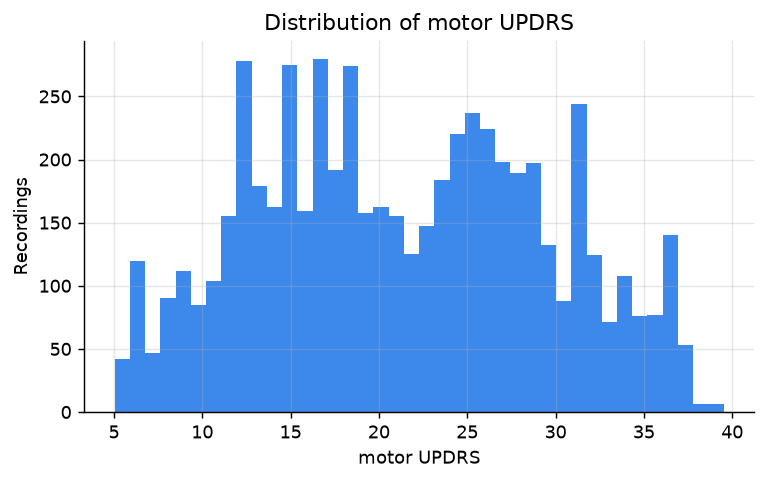

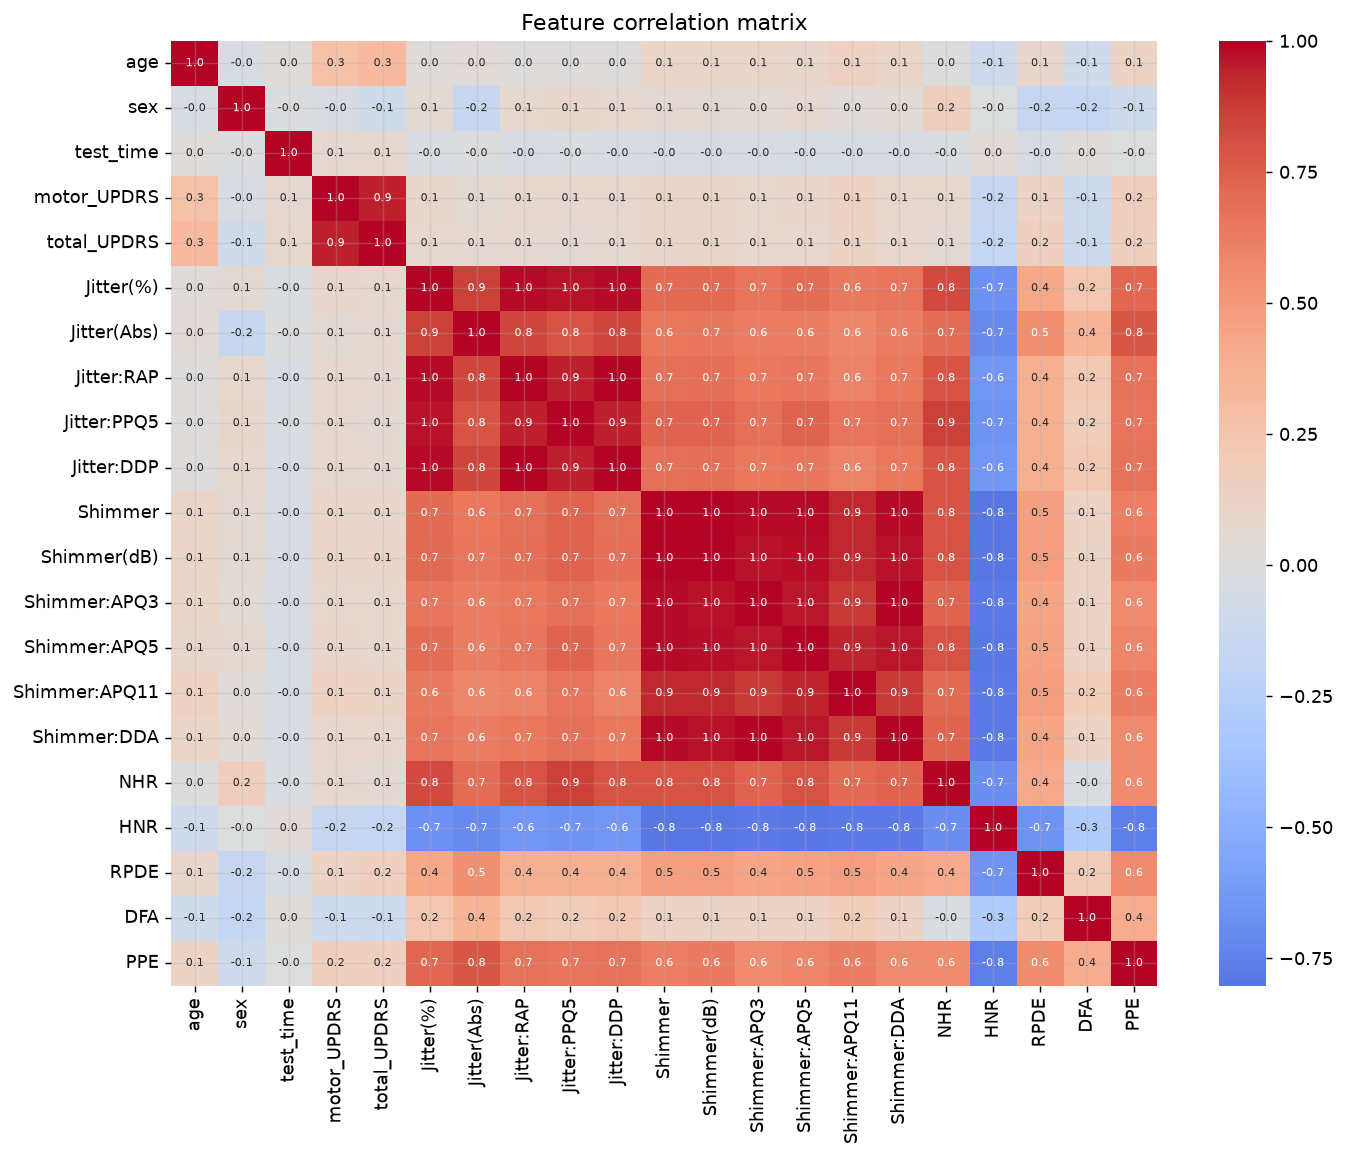

In [4]:
data = prepare_data(CONFIG["data"], seed=CONFIG["split_seed"])
print(json.dumps(data.report, indent=2))
skew = pd.DataFrame({"before": raw[data.report["log_transformed"]].skew(),
                     "after log1p": np.log1p(raw[data.report["log_transformed"]]).skew()}).round(2)
display(Markdown("**Skewness of the log-transformed features**")); display(skew)
plots.target_distribution(raw[TARGET], OUT / "target_distribution.png")
plots.correlation_heatmap(raw.drop(columns=["subject#"]), OUT / "correlation_heatmap.png")
display(Image(OUT / "target_distribution.png")); display(Image(OUT / "correlation_heatmap.png"))

## 4. Baselines (no optimisation)
All trained on all 18 features. The **default SVR** uses scikit-learn's defaults (C = 1, gamma = 'scale', epsilon = 0.1) and is the model that Cuckoo Search optimises.

In [5]:
results, preds = {}, {}
for name, model in baselines().items():
    model.fit(data.X_train, data.y_train)
    preds[name] = model.predict(data.X_test)
    results[name] = regression_metrics(data.y_test, preds[name])
pd.DataFrame(results).T.round(4)

,RMSE,MAE,R2,MAPE_%
Mean predictor,7.9914,6.8778,-0.0005,43.1174
Linear Regression,7.4675,6.3267,0.1264,38.3750
Default SVR,5.6724,4.4114,0.4959,26.5169


## 5. Cuckoo Search: joint hyperparameter tuning and feature selection

**Encoding.** Each nest is a position in [0, 1]^21:

| Dimensions | Meaning | Decoding |
|---|---|---|
| 1-3 | C, gamma, epsilon | log-scale between the bounds below |
| 4-21 | one per feature | feature used if value > 0.5 (threshold transfer to binary) |

**Fitness** = 3-fold cross-validated RMSE on the training set (lower is better). The test set is never seen during the search.

**Operators** (`src/cuckoo.py`):
1. **Levy flight**: new egg = nest + alpha * Levy(beta) * (nest - best) * N(0, 1), with Levy steps drawn by Mantegna's algorithm (beta = 1.5). Most steps are small (exploitation), occasional steps are long (exploration).
2. **Nest replacement**: the new egg replaces the nest it was laid from if it is fitter (greedy selection, as in Yang & Deb's reference code).
3. **Nest abandonment**: each component is discovered with probability pa = 0.25, and the nest is rebuilt by a random walk between two other nests (keeps diversity).
4. **Elitism**: the best nest is always kept.
5. **Warm start**: one initial nest is the default SVR with all features, so the search starts from the baseline.

In [6]:
display(pd.DataFrame(HYPERPARAMS, columns=["Hyperparameter", "Lower bound", "Upper bound"]).assign(Scale="log10"))
import src.cuckoo
display(Markdown("**Cuckoo Search implementation (`src/cuckoo.py`):**\n```python\n" + inspect.getsource(src.cuckoo) + "\n```"))

,Hyperparameter,Lower bound,Upper bound,Scale
0,C,0.1000,1000.0,log10
1,gamma,0.0001,10.0,log10
2,epsilon,0.0010,1.0,log10


**Cuckoo Search implementation (`src/cuckoo.py`):**
```python
"""Cuckoo Search (Yang & Deb, 2009), implemented from scratch for minimisation.

Biological inspiration: some cuckoo species lay eggs in other birds' nests. Each nest
holds one candidate solution (here: SVR hyperparameters + a feature subset). The algorithm uses:
  1. Levy flights      - new eggs are laid by long-tailed random jumps around current nests,
                         so most steps are small (exploitation) but some are very large
                         (exploration).
  2. Nest replacement  - a new egg replaces the nest it was laid from if it is fitter
                         (as in Yang & Deb's reference code; replacing a random nest lets one
                         good egg overwrite the whole population and the search stalls).
  3. Nest abandonment  - a fraction `pa` of eggs is discovered by the host bird and the
                         nest is rebuilt elsewhere (a biased random walk between nests).
  4. Elitism           - the best nest found so far is always kept.
"""
from math import gamma, pi, sin

import numpy as np


def levy_step(rng, size, beta=1.5):
    """Draw a Levy-distributed step with Mantegna's algorithm."""
    sigma_u = (gamma(1 + beta) * sin(pi * beta / 2)
               / (gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    u = rng.normal(0, sigma_u, size)
    v = rng.normal(0, 1, size)
    return u / np.abs(v) ** (1 / beta)


class CuckooSearch:
    def __init__(self, objective, dim, n_nests=10, n_generations=10, pa=0.25,
                 alpha=1.0, beta=1.5, seed=42, warm_start=None, verbose=True):
        self.objective = objective
        self.dim = dim
        self.n_nests = n_nests
        self.n_generations = n_generations
        self.pa = pa              # probability that an egg is discovered (nest abandoned)
        self.alpha = alpha        # Levy step-size scale; the step is also proportional to the
                                  # distance from the best nest, so it shrinks as nests converge
        self.beta = beta          # Levy exponent, 1 < beta <= 2
        self.rng = np.random.default_rng(seed)
        self.warm_start = [] if warm_start is None else list(warm_start)   # known-good starting nests
        self.verbose = verbose
        self.history = []         # best fitness after each generation (convergence curve)
        self.mean_history = []    # mean fitness of the population after each generation

    def _lay_eggs_by_levy_flight(self, nests, fitness, best):
        """Operator 1 + 2: Levy flight from every nest, keep the egg if it beats its own nest."""
        eggs = []
        for i in range(self.n_nests):
            # Step size scales with distance from the best nest, so the swarm is
            # pulled towards good regions while each nest keeps its own position.
            step = self.alpha * levy_step(self.rng, self.dim, self.beta) * (nests[i] - best)
            eggs.append(np.clip(nests[i] + step * self.rng.standard_normal(self.dim), 0, 1))
        # Each egg depends only on its own nest and the best nest, so all eggs of a
        # generation can be scored in one parallel batch.
        for i, (egg, f_egg) in enumerate(zip(eggs, self.objective.evaluate_many(eggs))):
            if f_egg < fitness[i]:
                nests[i], fitness[i] = egg, f_egg

    def _abandon_nests(self, nests, fitness):
        """Operator 3: each dimension of each nest is discovered with probability pa;
        discovered nests are rebuilt by a random walk between two other nests."""
        discovered = self.rng.random((self.n_nests, self.dim)) < self.pa
        p1, p2 = self.rng.permutation(self.n_nests), self.rng.permutation(self.n_nests)
        step = self.rng.random((self.n_nests, 1)) * (nests[p1] - nests[p2])
        new_nests = np.clip(nests + step * discovered, 0, 1)
        rebuilt = np.flatnonzero(discovered.any(axis=1))
        for i, f_new in zip(rebuilt, self.objective.evaluate_many(new_nests[rebuilt])):
            if f_new < fitness[i]:
                nests[i], fitness[i] = new_nests[i], f_new

    def run(self):
        nests = self.rng.random((self.n_nests, self.dim))
        # Warm start: seed the first nests with given positions (e.g. the default model),
        # so the search starts from the baseline and can only improve on it.
        for k, x in enumerate(self.warm_start[:self.n_nests]):
            nests[k] = x
        fitness = np.array(self.objective.evaluate_many(nests))
        self.history.append(fitness.min())
        self.mean_history.append(fitness.mean())
        self._log(0, fitness)

        for gen in range(1, self.n_generations + 1):
            best = nests[fitness.argmin()].copy()     # Operator 4: elitism
            self._lay_eggs_by_levy_flight(nests, fitness, best)
            self._abandon_nests(nests, fitness)
            self.history.append(fitness.min())
            self.mean_history.append(fitness.mean())
            self._log(gen, fitness)

        i_best = fitness.argmin()
        return nests[i_best], fitness[i_best]

    def _log(self, gen, fitness):
        if self.verbose:
            print(f"  [CS] generation {gen:2d}/{self.n_generations}  best={fitness.min():.5f}  "
                  f"mean={fitness.mean():.5f}  evaluations={self.objective.n_evals}", flush=True)

```

### 5.1 Operator check on standard test functions

Before trusting Cuckoo Search on the SVR, its operators are checked on four standard benchmark functions in 10
dimensions, each with known global minimum f = 0 (`src/benchmarks.py`):

| Function | Domain | Difficulty |
|---|---|---|
| Sphere | [-100, 100] | smooth, one minimum: tests basic convergence |
| Rastrigin | [-5.12, 5.12] | about 10^10 local minima: tests escaping local optima |
| Rosenbrock | [-5, 10] | narrow curved valley: tests fine convergence |
| Ackley | [-32.768, 32.768] | flat outer region with many small dips |

Each method gets 10 seeds and the same budget of evaluations. Three methods are compared:
* **Cuckoo Search**: the implementation used in this project.
* **Cuckoo Search (random-nest replacement)**: an ablation in which a new egg replaces a *randomly chosen* nest
  instead of its own (a reading of the original paper's pseudocode, and our first version). One good egg can then
  overwrite the whole population, so diversity collapses and the search stalls.
* **Random Search**: uniform sampling, the non-bio-inspired reference.

10 seeds x 9000 evaluations per run, dimension 10, 6 s


Method,Cuckoo Search,Cuckoo Search (random-nest replacement),Random Search
Function,,,
Ackley,0.278,11.9,17.3
Rastrigin,16.1,50.4,72.4
Rosenbrock,11.1,712,1.52e+04
Sphere,0.019,715,5.41e+03


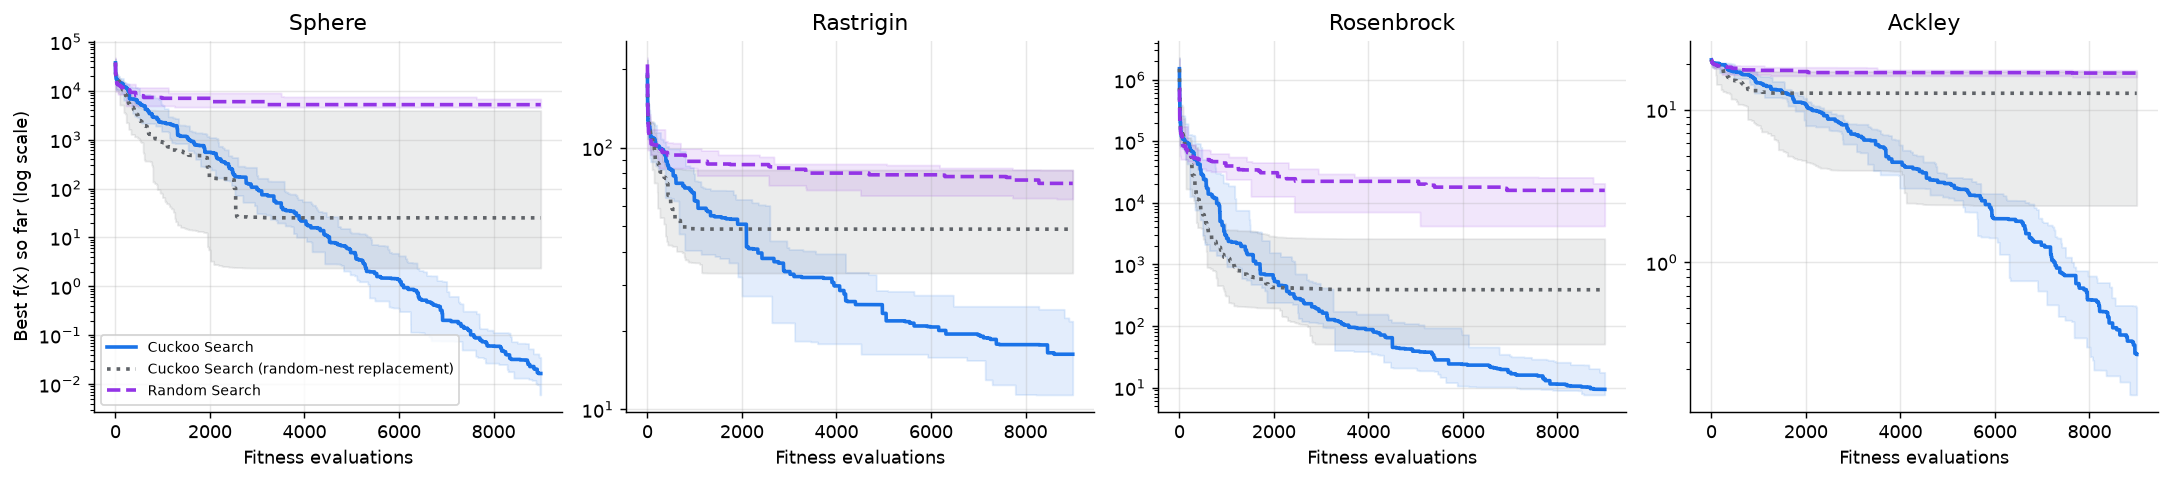

In [7]:
from src.benchmarks import FUNCTIONS, BenchmarkObjective
from src.cuckoo import levy_step

class CuckooRandomReplacement(CuckooSearch):
    """Ablation: the Levy-flight egg replaces a randomly chosen nest j instead of its own nest i."""
    def _lay_eggs_by_levy_flight(self, nests, fitness, best):
        for i in range(self.n_nests):
            step = self.alpha * levy_step(self.rng, self.dim, self.beta) * (nests[i] - best)
            egg = np.clip(nests[i] + step * self.rng.standard_normal(self.dim), 0, 1)
            f_egg = self.objective(egg)
            j = self.rng.integers(self.n_nests)
            if f_egg < fitness[j]:
                nests[j], fitness[j] = egg, f_egg

BENCH = {"dim": 10, "nests": 25, "generations": 200, "budget": 9000, "seeds": list(range(1, 11))}
budget = BENCH["budget"]   # every method is compared over exactly the same number of evaluations
t = time.time()
bench_rows, bench_curves = [], {}
for fname in FUNCTIONS:
    bench_curves[fname] = {}
    for method in ["Cuckoo Search", "Cuckoo Search (random-nest replacement)", "Random Search"]:
        finals, runs = [], []
        for s in BENCH["seeds"]:
            obj = BenchmarkObjective(fname)
            if method == "Random Search":
                random_search(obj, BENCH["dim"], budget, seed=s + 1000, verbose=False)
            else:
                cls = CuckooSearch if method == "Cuckoo Search" else CuckooRandomReplacement
                cls(obj, BENCH["dim"], n_nests=BENCH["nests"], n_generations=BENCH["generations"],
                    pa=CONFIG["pa"], alpha=CONFIG["alpha"], beta=CONFIG["beta"], seed=s, verbose=False).run()
            assert obj.n_evals >= budget
            curve = np.array([e["best_so_far"] for e in obj.log])[:budget]
            runs.append(curve); finals.append(curve[-1])
        bench_curves[fname][method] = np.array(runs)
        bench_rows.append({"Function": fname, "Method": method, "mean best f": np.mean(finals),
                           "std": np.std(finals), "median": np.median(finals), "best run": np.min(finals)})
timings["benchmarks_s"] = time.time() - t
bench_df = pd.DataFrame(bench_rows)
bench_df.to_csv(OUT / "benchmark_functions.csv", index=False)
print(f"{len(BENCH['seeds'])} seeds x {budget} evaluations per run, dimension {BENCH['dim']}, {timings['benchmarks_s']:.0f} s")
display(bench_df.pivot(index="Function", columns="Method", values="mean best f")
        [["Cuckoo Search", "Cuckoo Search (random-nest replacement)", "Random Search"]].map(lambda v: f"{v:.3g}"))
plots.benchmark_convergence(bench_curves, OUT / "benchmark_convergence.png")
display(Image(OUT / "benchmark_convergence.png"))

### 5.2 Main Cuckoo Search run on the SVR

In [8]:
D = dim(data.n_features)
warm = [default_position(data.n_features)]

def run_cuckoo(seed, verbose):
    obj = Objective(data.X_train, data.y_train, data.feature_names, folds=CONFIG["cv_folds"], seed=CONFIG["split_seed"])
    cs = CuckooSearch(obj, D, n_nests=CONFIG["nests"], n_generations=CONFIG["generations"], pa=CONFIG["pa"],
                      alpha=CONFIG["alpha"], beta=CONFIG["beta"], seed=seed, warm_start=warm, verbose=verbose)
    x, f = cs.run()
    return cs, obj, x, f

def run_random(seed, n_evals, verbose):
    obj = Objective(data.X_train, data.y_train, data.feature_names, folds=CONFIG["cv_folds"], seed=CONFIG["split_seed"])
    x, f = random_search(obj, D, n_evals, seed=seed + 1000, verbose=verbose)
    return obj, x, f

def fit_and_test(x):
    params, mask = decode(x)
    model = build_svr(**params).fit(data.X_train[:, mask], data.y_train)
    return model, params, mask, model.predict(data.X_test[:, mask])

t = time.time()
cs, cs_obj, cs_x, cs_cv = run_cuckoo(CONFIG["main_seed"], verbose=True)
timings["cuckoo_search_s"] = time.time() - t
cs_params, cs_mask = decode(cs_x)
print(f"\nFinished in {timings['cuckoo_search_s']/60:.1f} min, {cs_obj.n_evals} fitness evaluations")
print(f"Default SVR CV RMSE (warm-start nest): {cs_obj.log[0]['fitness']:.4f}")
print(f"Best CV RMSE: {cs_cv:.4f}")
print("Best hyperparameters:", {k: float(f"{v:.4g}") for k, v in cs_params.items()})
print(f"Selected {cs_mask.sum()} of {data.n_features} features:", np.array(data.feature_names)[cs_mask].tolist())

  [CS] generation  0/20  best=5.65407  mean=6.87245  evaluations=20


  [CS] generation  1/20  best=4.94559  mean=6.68483  evaluations=60


  [CS] generation  2/20  best=4.94559  mean=6.49616  evaluations=100


  [CS] generation  3/20  best=4.94559  mean=6.29830  evaluations=140


  [CS] generation  4/20  best=4.92002  mean=5.99344  evaluations=180


  [CS] generation  5/20  best=4.90316  mean=5.77564  evaluations=220


... (12 outputs left out)

  [CS] generation 18/20  best=4.44569  mean=4.87873  evaluations=739


  [CS] generation 19/20  best=4.44569  mean=4.85631  evaluations=779


  [CS] generation 20/20  best=4.42561  mean=4.78400  evaluations=819



Finished in 12.2 min, 819 fitness evaluations
Default SVR CV RMSE (warm-start nest): 5.9634
Best CV RMSE: 4.4256
Best hyperparameters: {'C': 15.68, 'gamma': 0.8253, 'epsilon': 0.03935}
Selected 9 of 18 features: ['age', 'sex', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:DDP', 'Shimmer', 'NHR', 'HNR', 'DFA']


## 6. Random Search with the same budget

  [RS] evaluation  25/819  best=5.51179


  [RS] evaluation  50/819  best=4.88225


  [RS] evaluation  75/819  best=4.88225


  [RS] evaluation 100/819  best=4.78032


  [RS] evaluation 125/819  best=4.78032


  [RS] evaluation 150/819  best=4.78032


... (24 outputs left out)

  [RS] evaluation 775/819  best=4.78032


  [RS] evaluation 800/819  best=4.78032


  [RS] evaluation 819/819  best=4.78032



Best CV RMSE: 4.7803 (Cuckoo Search: 4.4256)
Best hyperparameters: {'C': 0.6919, 'gamma': 1.866, 'epsilon': 0.001969} | 8 features


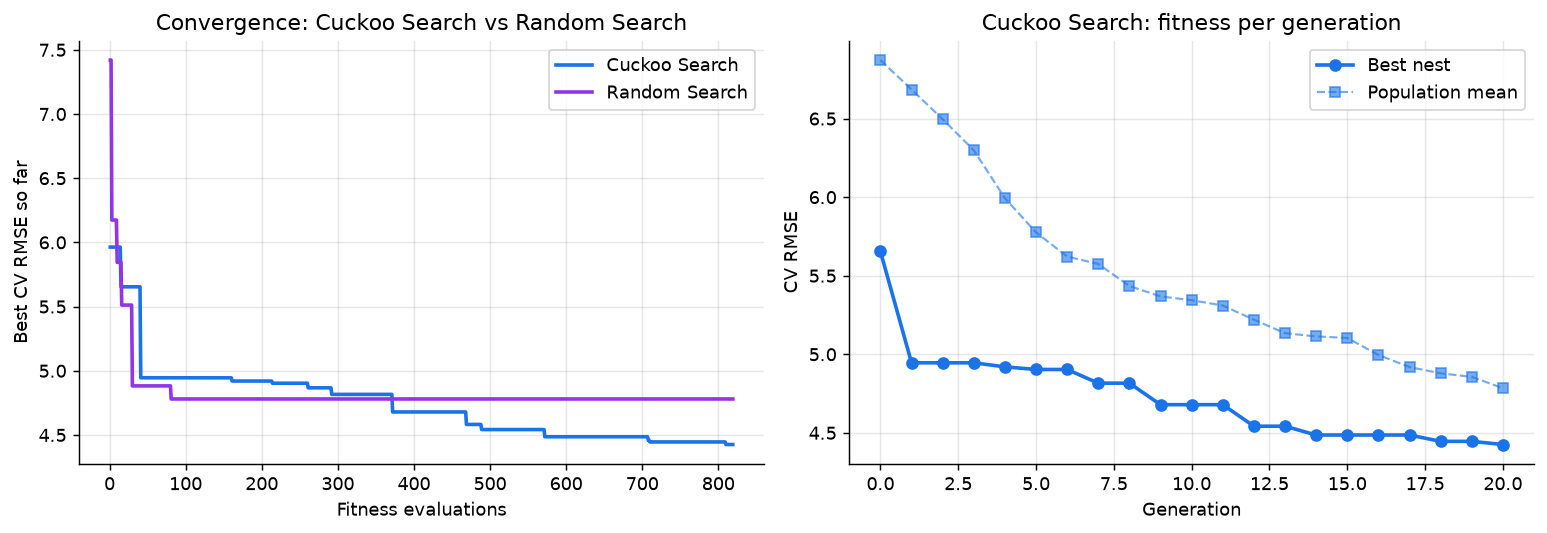

Best CV RMSE per generation: [5.6541, 4.9456, 4.9456, 4.9456, 4.92, 4.9032, 4.9032, 4.8161, 4.8161, 4.6792, 4.6792, 4.6792, 4.5421, 4.5421, 4.4861, 4.4861, 4.4861, 4.4861, 4.4457, 4.4457, 4.4256]


In [9]:
t = time.time()
rs_obj, rs_x, rs_cv = run_random(CONFIG["main_seed"], cs_obj.n_evals, verbose=True)
timings["random_search_s"] = time.time() - t
rs_params, rs_mask = decode(rs_x)
print(f"\nBest CV RMSE: {rs_cv:.4f} (Cuckoo Search: {cs_cv:.4f})")
print("Best hyperparameters:", {k: float(f"{v:.4g}") for k, v in rs_params.items()}, f"| {rs_mask.sum()} features")
plots.convergence(cs_obj.log, rs_obj.log, cs.history, cs.mean_history, OUT / "convergence.png")
display(Image(OUT / "convergence.png"))
pd.DataFrame(cs_obj.log).to_csv(OUT / "search_log_cuckoo.csv", index=False)
pd.DataFrame(rs_obj.log).to_csv(OUT / "search_log_random.csv", index=False)
print("Best CV RMSE per generation:", [round(float(v), 4) for v in cs.history])

## 7. Test-set evaluation: baseline vs optimised

In [10]:
cs_model, _, _, preds["Cuckoo-SVR"] = fit_and_test(cs_x)
_, _, _, preds["Random Search SVR"] = fit_and_test(rs_x)
results["Random Search SVR"] = regression_metrics(data.y_test, preds["Random Search SVR"])
results["Cuckoo-SVR"] = regression_metrics(data.y_test, preds["Cuckoo-SVR"])
joblib.dump({"model": cs_model, "params": cs_params, "features": np.array(data.feature_names)[cs_mask].tolist()},
            OUT / "cuckoo_svr.joblib")
display(Markdown("### All models, test set")); display(pd.DataFrame(results).T.round(4))

cmp_default = compare(results["Default SVR"], results["Cuckoo-SVR"])
display(Markdown("### Default SVR (no optimisation) vs Cuckoo-optimised SVR")); display(cmp_default.round(4))
cmp_rs = compare(results["Random Search SVR"], results["Cuckoo-SVR"], names=("Random Search SVR", "Cuckoo-SVR"))
display(Markdown("### Random Search vs Cuckoo Search (same budget)")); display(cmp_rs.round(4))

display(Markdown("### Configurations"))
display(pd.DataFrame({
    "Default SVR": {**{k: str(v) for k, v in DEFAULT_PARAMS.items()}, "features used": data.n_features},
    "Random Search SVR": {**{k: f"{v:.4g}" for k, v in rs_params.items()}, "features used": int(rs_mask.sum())},
    "Cuckoo-SVR": {**{k: f"{v:.4g}" for k, v in cs_params.items()}, "features used": int(cs_mask.sum())},
}))

### All models, test set

,RMSE,MAE,R2,MAPE_%
Mean predictor,7.9914,6.8778,-0.0005,43.1174
Linear Regression,7.4675,6.3267,0.1264,38.3750
Default SVR,5.6724,4.4114,0.4959,26.5169
Random Search SVR,4.6934,3.2970,0.6549,19.5102
Cuckoo-SVR,4.3465,3.0659,0.7040,17.9679


### Default SVR (no optimisation) vs Cuckoo-optimised SVR

,Default SVR,Cuckoo-SVR,Change,Improvement_%,Better
Metric,,,,,
RMSE,5.6724,4.3465,-1.3259,23.3744,yes
MAE,4.4114,3.0659,-1.3455,30.5009,yes
R2,0.4959,0.7040,0.2081,41.9672,yes
MAPE_%,26.5169,17.9679,-8.5490,32.2397,yes


### Random Search vs Cuckoo Search (same budget)

,Random Search SVR,Cuckoo-SVR,Change,Improvement_%,Better
Metric,,,,,
RMSE,4.6934,4.3465,-0.3469,7.3917,yes
MAE,3.2970,3.0659,-0.2311,7.0092,yes
R2,0.6549,0.7040,0.0491,7.5027,yes
MAPE_%,19.5102,17.9679,-1.5423,7.9051,yes


### Configurations

,Default SVR,Random Search SVR,Cuckoo-SVR
C,1.0,0.6919,15.68
gamma,scale,1.866,0.8253
epsilon,0.1,0.001969,0.03935
features used,18,8,9


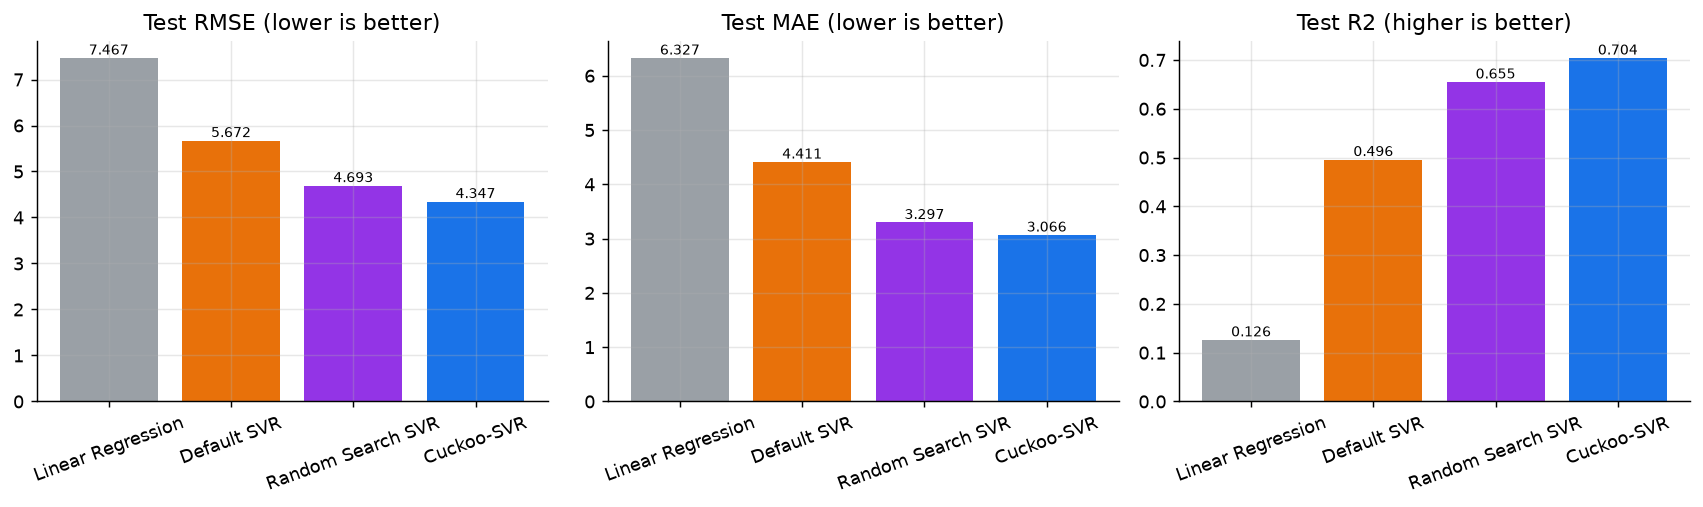

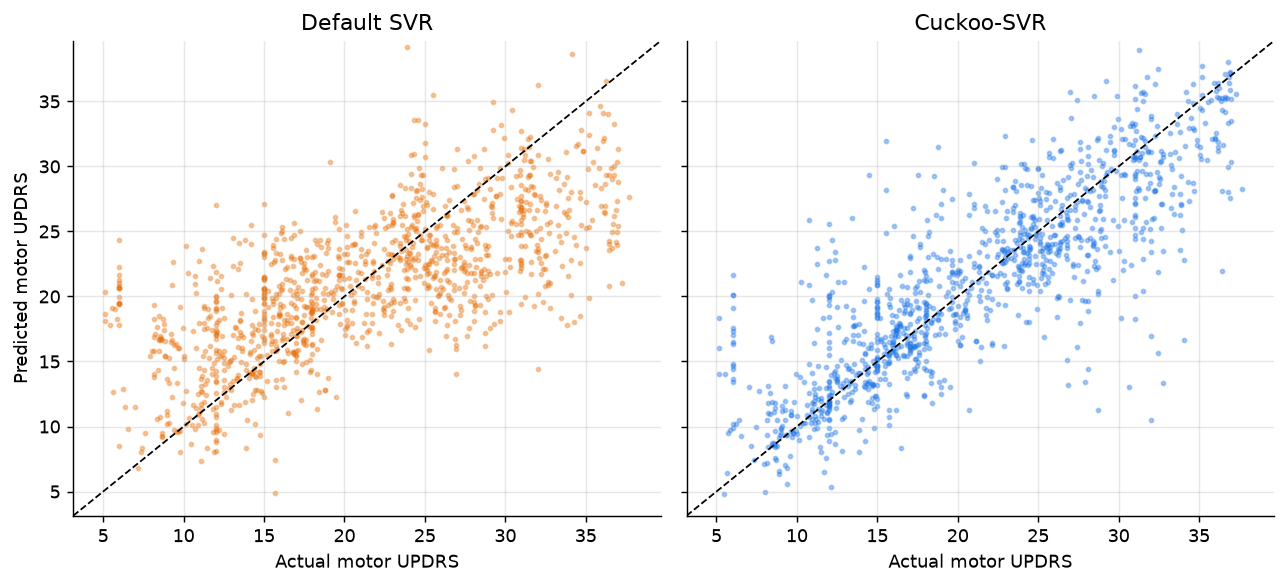

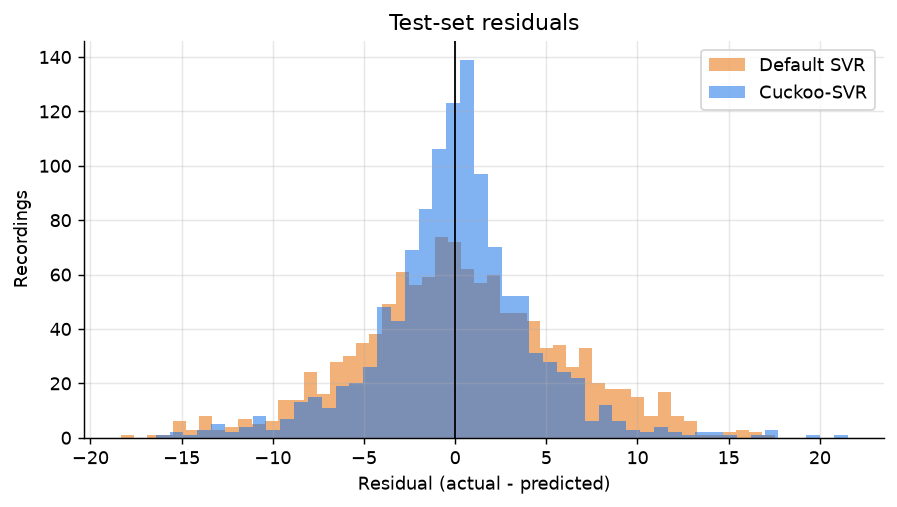

In [11]:
plots.metric_bars({k: results[k] for k in ["Linear Regression", "Default SVR", "Random Search SVR", "Cuckoo-SVR"]},
                  OUT / "metric_comparison.png")
plots.predicted_vs_actual(data.y_test, {k: preds[k] for k in ["Default SVR", "Cuckoo-SVR"]}, OUT / "predicted_vs_actual.png")
plots.residuals(data.y_test, {k: preds[k] for k in ["Default SVR", "Cuckoo-SVR"]}, OUT / "residuals.png")
for f in ["metric_comparison", "predicted_vs_actual", "residuals"]:
    display(Image(OUT / f"{f}.png"))

## 8. Learning curves

RMSE on the training folds and on the held-out folds as the training set grows (5-fold CV on the training set,
the test set is not used). A gap between the two curves shows overfitting, a high pair of curves shows underfitting.

train_size  train_RMSE  validation_RMSE  validation_std
Default SVR 0         376      6.4511           7.0310          0.1742
            1         859      6.1029           6.6563          0.1471
            2        1342      5.9254           6.3488          0.1282
            3        1826      5.8362           6.1437          0.1262
            4        2309      5.8065           6.0938          0.1512
            5        2793      5.7547           6.0123          0.1479
            6        3276      5.6872           5.9336          0.1600
            7        3760      5.6327           5.8864          0.1627
Cuckoo-SVR  0         376      1.1475           6.0711          0.1722
            1         859      2.1752           5.2199          0.0880
            2        1342      2.3135           5.0277          0.1494
            3        1826      2.4620           4.7635          0.1046
            4        2309      2.6357           4.6353          0.0550
            5        2793      2.6684           4.5392          0.0907
            6        3276      2.7363           4.3933          0.1061
            7        3760      2.7547           4.3422          0.0608

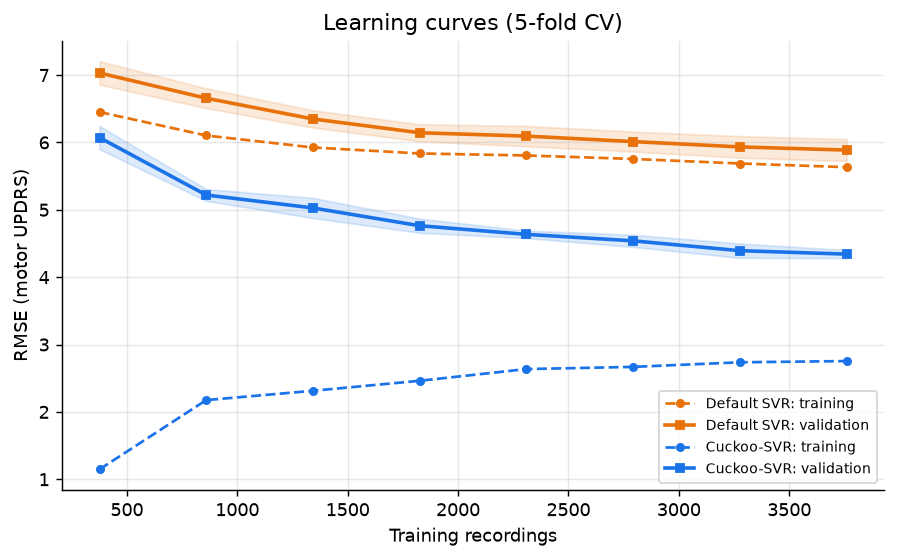

In [12]:
from sklearn.model_selection import KFold, learning_curve
t = time.time()
lc = {}
for name, model, cols in [("Default SVR", build_svr(**DEFAULT_PARAMS), np.ones(data.n_features, bool)),
                          ("Cuckoo-SVR", build_svr(**cs_params), cs_mask)]:
    sizes, tr, va = learning_curve(model, data.X_train[:, cols], data.y_train,
                                   train_sizes=np.linspace(0.1, 1.0, 8),
                                   cv=KFold(5, shuffle=True, random_state=CONFIG["split_seed"]),
                                   scoring="neg_root_mean_squared_error", n_jobs=-1)
    lc[name] = (sizes, -tr, -va)
timings["learning_curves_s"] = time.time() - t
lc_df = pd.concat({name: pd.DataFrame({"train_size": s, "train_RMSE": tr.mean(1), "validation_RMSE": va.mean(1),
                                       "validation_std": va.std(1)}) for name, (s, tr, va) in lc.items()})
lc_df.to_csv(OUT / "learning_curves.csv")
display(lc_df.round(4))
plots.learning_curves(lc, OUT / "learning_curves.png")
display(Image(OUT / "learning_curves.png"))

## 9. Robustness: 10 independent runs
Metaheuristics are stochastic, so a single run can be lucky. Both optimisers are re-run with 10 different seeds (same budget each time) and every resulting model is scored on the test set.

In [13]:
t = time.time()
per_seed, feature_counts = [], np.zeros(data.n_features)
for s in CONFIG["robustness_seeds"]:
    cs_s, obj_s, x_s, f_s = run_cuckoo(s, verbose=False)
    _, xr_s, fr_s = run_random(s, obj_s.n_evals, verbose=False)
    _, _, mask_s, p_cs = fit_and_test(x_s)
    _, _, _, p_rs = fit_and_test(xr_s)
    feature_counts += mask_s
    row = {"seed": s, "Cuckoo Search": regression_metrics(data.y_test, p_cs)["RMSE"],
           "Random Search": regression_metrics(data.y_test, p_rs)["RMSE"],
           "CS_cv": f_s, "RS_cv": fr_s, "CS_R2": regression_metrics(data.y_test, p_cs)["R2"],
           "CS_features": int(mask_s.sum())}
    per_seed.append(row)
    print(f"seed {s:2d}: Cuckoo {row['Cuckoo Search']:.4f} | Random {row['Random Search']:.4f} | "
          f"{'Cuckoo' if row['Cuckoo Search'] < row['Random Search'] else 'Random'} better", flush=True)
timings["robustness_s"] = time.time() - t
seeds_df = pd.DataFrame(per_seed).set_index("seed")
seeds_df.to_csv(OUT / "robustness_seeds.csv")

seed  1: Cuckoo 4.3611 | Random 4.6095 | Cuckoo better


seed  2: Cuckoo 4.3017 | Random 4.7273 | Cuckoo better


seed  3: Cuckoo 4.3509 | Random 4.7528 | Cuckoo better


seed  4: Cuckoo 4.3270 | Random 4.5045 | Cuckoo better


seed  5: Cuckoo 4.4001 | Random 4.3698 | Random better


seed  6: Cuckoo 4.3028 | Random 4.8709 | Cuckoo better


seed  7: Cuckoo 4.3239 | Random 4.4554 | Cuckoo better


seed  8: Cuckoo 4.4195 | Random 4.6045 | Cuckoo better


seed  9: Cuckoo 4.3798 | Random 4.7631 | Cuckoo better


seed 10: Cuckoo 4.3952 | Random 4.3030 | Random better


,mean test RMSE,std,best,worst,runs beating default SVR,mean improvement over default %
Cuckoo Search,4.3562,0.0419,4.3017,4.4195,10/10,23.2035
Random Search,4.5961,0.1858,4.3030,4.8709,10/10,18.9747


Cuckoo Search beat Random Search in 8/10 runs
Wilcoxon signed-rank, Cuckoo < Random Search : p = 0.0049
Wilcoxon signed-rank, Cuckoo < Default SVR   : p = 0.0010


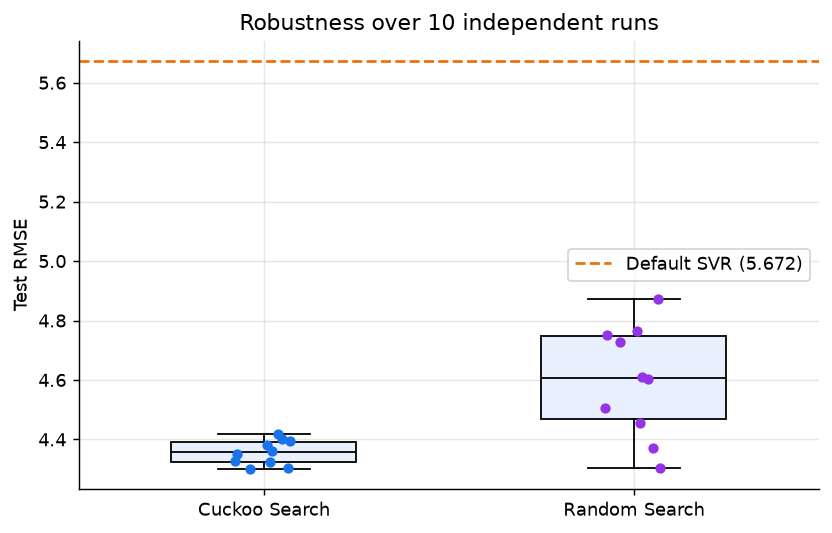

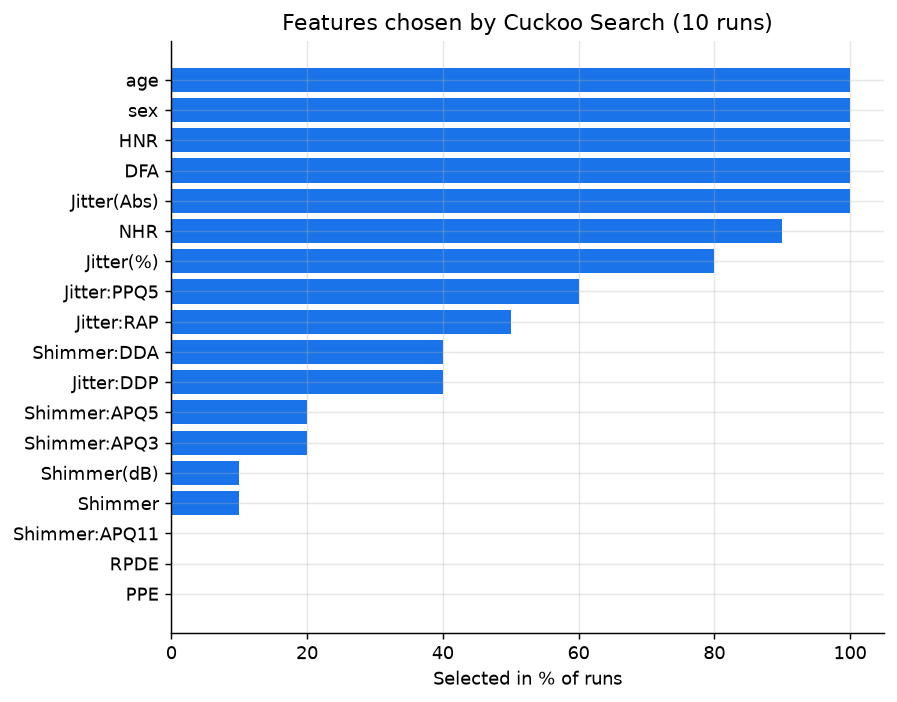

In [14]:
d_rmse = results["Default SVR"]["RMSE"]
summary = pd.DataFrame({
    "mean test RMSE": seeds_df[["Cuckoo Search", "Random Search"]].mean(),
    "std": seeds_df[["Cuckoo Search", "Random Search"]].std(),
    "best": seeds_df[["Cuckoo Search", "Random Search"]].min(),
    "worst": seeds_df[["Cuckoo Search", "Random Search"]].max(),
    "runs beating default SVR": (seeds_df[["Cuckoo Search", "Random Search"]] < d_rmse).sum().astype(str) + f"/{len(seeds_df)}",
})
summary["mean improvement over default %"] = 100 * (d_rmse - summary["mean test RMSE"]) / d_rmse
display(summary.round(4))
wins = int((seeds_df["Cuckoo Search"] < seeds_df["Random Search"]).sum())
stat_rs = wilcoxon(seeds_df["Cuckoo Search"], seeds_df["Random Search"], alternative="less")
stat_def = wilcoxon(seeds_df["Cuckoo Search"] - d_rmse, alternative="less")
print(f"Cuckoo Search beat Random Search in {wins}/{len(seeds_df)} runs")
print(f"Wilcoxon signed-rank, Cuckoo < Random Search : p = {stat_rs.pvalue:.4f}")
print(f"Wilcoxon signed-rank, Cuckoo < Default SVR   : p = {stat_def.pvalue:.4f}")
plots.seed_boxplot(seeds_df[["Cuckoo Search", "Random Search"]].to_dict("list"), d_rmse, OUT / "robustness_boxplot.png")
plots.selected_features(data.feature_names, feature_counts, len(seeds_df), OUT / "feature_selection_frequency.png")
display(Image(OUT / "robustness_boxplot.png")); display(Image(OUT / "feature_selection_frequency.png"))

## 10. Save all results

In [15]:
timings["total_s"] = time.time() - T0
record = {
    "run_finished": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "config": CONFIG, "preprocessing": data.report,
    "cuckoo_evaluations": cs_obj.n_evals,
    "default_params": DEFAULT_PARAMS,
    "cuckoo": {"params": cs_params, "features": np.array(data.feature_names)[cs_mask].tolist(), "cv_rmse": cs_cv},
    "random_search": {"params": rs_params, "features": np.array(data.feature_names)[rs_mask].tolist(), "cv_rmse": rs_cv},
    "test_metrics": results,
    "improvement_over_default_%": cmp_default["Improvement_%"].to_dict(),
    "improvement_over_random_search_%": cmp_rs["Improvement_%"].to_dict(),
    "cuckoo_history_best": [float(v) for v in cs.history],
    "cuckoo_history_mean": [float(v) for v in cs.mean_history],
    "robustness": {"summary": summary.to_dict(), "cuckoo_wins": wins,
                   "wilcoxon_p_vs_random": float(stat_rs.pvalue), "wilcoxon_p_vs_default": float(stat_def.pvalue)},
    "benchmark_functions": bench_df.to_dict("records"),
    "learning_curves": {name: {"train_sizes": s.tolist(), "train_rmse": tr.mean(1).tolist(),
                               "validation_rmse": va.mean(1).tolist()} for name, (s, tr, va) in lc.items()},
    "timings_s": timings,
}
(OUT / "results.json").write_text(json.dumps(record, indent=2, default=str))
pd.DataFrame(results).T.to_csv(OUT / "test_metrics.csv")
cmp_default.to_csv(OUT / "comparison_default_vs_cuckoo.csv")
cmp_rs.to_csv(OUT / "comparison_random_vs_cuckoo.csv")
summary.to_csv(OUT / "robustness_summary.csv")
print(f"Total run time: {timings['total_s']/60:.1f} min | finished {record['run_finished']}")
print("\nSaved files:")
for f in sorted(OUT.iterdir()):
    print(f"  {f.name:38s} {f.stat().st_size/1024:8.1f} KB")

Total run time: 173.2 min | finished 2026-11-06 06:09:12

Saved files:
  benchmark_convergence.png                 146.4 KB
  benchmark_functions.csv                     1.3 KB
  comparison_default_vs_cuckoo.csv            0.4 KB
  comparison_random_vs_cuckoo.csv             0.4 KB
  convergence.png                            75.2 KB
  correlation_heatmap.png                   256.4 KB
  cuckoo_svr.joblib                         384.1 KB
  feature_selection_frequency.png            45.6 KB
  learning_curves.csv                         1.2 KB
  learning_curves.png                        67.7 KB
  metric_comparison.png                      66.9 KB
  nbconvert_log.txt                           0.3 KB
  predicted_vs_actual.png                   150.7 KB
  residuals.png                              27.6 KB
  results.json                                9.0 KB
  robustness_boxplot.png                     27.8 KB
  robustness_seeds.csv                        1.0 KB
  robustness_summary.csv    

## 11. Summary

In [16]:
r = cmp_default.loc
print(f"Test RMSE : default SVR {r['RMSE','Default SVR']:.3f} -> Cuckoo-SVR {r['RMSE','Cuckoo-SVR']:.3f} ({r['RMSE','Improvement_%']:.1f}% better)")
print(f"Test MAE  : default SVR {r['MAE','Default SVR']:.3f} -> Cuckoo-SVR {r['MAE','Cuckoo-SVR']:.3f} ({r['MAE','Improvement_%']:.1f}% better)")
print(f"Test R2   : default SVR {r['R2','Default SVR']:.3f} -> Cuckoo-SVR {r['R2','Cuckoo-SVR']:.3f}")
print(f"Features  : {data.n_features} -> {int(cs_mask.sum())}")
print(f"Over {len(seeds_df)} runs: Cuckoo mean test RMSE {summary.loc['Cuckoo Search','mean test RMSE']:.3f} "
      f"+/- {summary.loc['Cuckoo Search','std']:.3f} vs Random Search {summary.loc['Random Search','mean test RMSE']:.3f} "
      f"+/- {summary.loc['Random Search','std']:.3f}; Cuckoo won {wins}/{len(seeds_df)} runs")

Test RMSE : default SVR 5.672 -> Cuckoo-SVR 4.347 (23.4% better)
Test MAE  : default SVR 4.411 -> Cuckoo-SVR 3.066 (30.5% better)
Test R2   : default SVR 0.496 -> Cuckoo-SVR 0.704
Features  : 18 -> 9
Over 10 runs: Cuckoo mean test RMSE 4.356 +/- 0.042 vs Random Search 4.596 +/- 0.186; Cuckoo won 8/10 runs
